# Hybrid Quantum-Classical Term Deposit Campaign Pipeline - end-to-end notebook

This notebook walks through the three linked stages. Heavy computations (5x5 nested CV, QAOA optimisation, noisy
simulations, bootstrap) are produced by `python run_all.py` and loaded from `results/`; every stage also has **live
cells** that recompute key quantities on the spot so the numbers can be checked without trusting the files.

Set `RERUN_PIPELINE = True` to regenerate everything from scratch first (about 35 minutes on 2 CPU cores).

**customer_id chain:** Stage 1 writes `stage1_predictions.csv` -> Stage 2 reads its top 10 -> Stage 3 reads Stage 2's six.

In [1]:
import sys, os, json, warnings, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RERUN_PIPELINE = False
if RERUN_PIPELINE:
    subprocess.run([sys.executable, str(ROOT / "run_all.py")], check=True, cwd=ROOT)
from qcampaign import config, data, utils
R = config.RESULTS
print(json.dumps(utils.load_json(R / "environment.json"), indent=1)[:1500])

{
 "timestamp_utc": "2026-11-10T21:28:19+00:00",
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "cpu_count": 2,
 "packages": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "pandas": "3.0.5",
  "scikit-learn": "1.9.1",
  "joblib": "1.6.0",
  "openpyxl": "3.1.5",
  "matplotlib": "3.11.2",
  "qiskit": "2.6.2",
  "qiskit-aer": "0.18.2",
  "qiskit-ibm-runtime": "0.52.0",
  "qiskit-machine-learning": "0.9.1"
 },
 "seeds": {
  "global": 42,
  "cv_outer": 42,
  "cv_inner": 7,
  "vqc_init": 42,
  "bootstrap": 2026,
  "qaoa_init": 42,
  "qaoa_sampler": 1234,
  "transpiler": 42,
  "stage3_sampler": 5678,
  "noise_sim": 91011,
  "monte_carlo": 2468
 },
 "quick_mode": false,
 "cv": {
  "outer": "5x5",
  "inner": 5
 },
 "shots": {
  "qaoa": 8192,
  "stage3": 8192
 },
 "monte_carlo_samples": 1000000,
 "noisy_backends": [
  "FakeTorino",
  "FakeBrisbane"
 ]
}


## 0. Data, integrity checks and the customer_id assumption

In [2]:
d = data.load()
print(d.checks)
print()
print(d.id_mapping_note)
d.train.head()

{'n_train': 300, 'n_test': 100, 'n_stage2': 400, 'train_positives': 35, 'train_ids_unique': True, 'test_ids_unique': True, 'train_test_overlap': 0, 'all_test_ids_in_stage2': True, 'missing_values_train': 0, 'missing_values_test': 0}

customer_id provided in Stage1_Test (updated organiser release); validated against Stage2_Data


,customer_id,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,C0273,51,technician,married,primary,no,1550,no,no,unknown,20,jun,5,-1,0,unknown,0
1,C0353,51,self-employed,married,secondary,yes,34,no,yes,cellular,7,jul,1,-1,0,unknown,0
2,C0201,32,services,married,tertiary,no,4908,no,yes,cellular,13,may,2,-1,0,unknown,0
3,C0014,43,blue-collar,married,secondary,no,10910,yes,no,cellular,15,may,2,-1,0,unknown,0
4,C0308,37,management,married,tertiary,no,5355,no,no,telephone,17,feb,4,-1,0,unknown,1


## 1. Stage 1 - subscription prediction

Candidates: classical baselines (engineered logistic regression, random forest, Gaussian-kernel LR control), two
quantum models (fidelity quantum kernel with an IQP feature map on 6 qubits + kernel logistic regression; data
re-uploading VQC on 6 qubits) and a hybrid ensemble. Nested CV: outer 5-fold x 5 repeats, inner 5-fold tuning on log
loss; all preprocessing/selection fitted inside training folds. Production model chosen by the **pre-declared** rule
(lowest mean log loss).

,roc_auc,pr_auc,brier,log_loss,precision@10pct,recall@10pct,calib_slope,roc_auc_sd,pr_auc_sd,brier_sd,log_loss_sd
model,,,,,,,,,,,
lr_compact,0.6857,0.3054,0.0943,0.3348,0.2667,0.2286,0.9062,0.0150,0.0130,0.0009,0.0037
hybrid_ensemble,0.6898,0.3001,0.0947,0.3349,0.2800,0.2400,0.8614,0.0147,0.0185,0.0008,0.0033
qk_klr,0.6839,0.2731,0.0980,0.3411,0.2867,0.2457,0.7232,0.0216,0.0323,0.0031,0.0065
vqc,0.6840,0.2963,0.0950,0.3414,0.2667,0.2286,0.7077,0.0202,0.0210,0.0017,0.0078
rbf_klr,0.6764,0.2763,0.0966,0.3415,0.2267,0.1943,0.7261,0.0182,0.0170,0.0021,0.0075
rf,0.6369,0.2440,0.1003,0.3510,0.2733,0.2343,0.6274,0.0129,0.0358,0.0007,0.0032
lr_onehot,0.5711,0.1683,0.1026,0.3583,0.1867,0.1600,0.7873,0.0294,0.0304,0.0011,0.0044
prior,0.5000,0.1167,0.1031,0.3602,0.1667,0.1429,0.8040,0.0000,0.0000,0.0000,0.0000


chosen: lr_compact


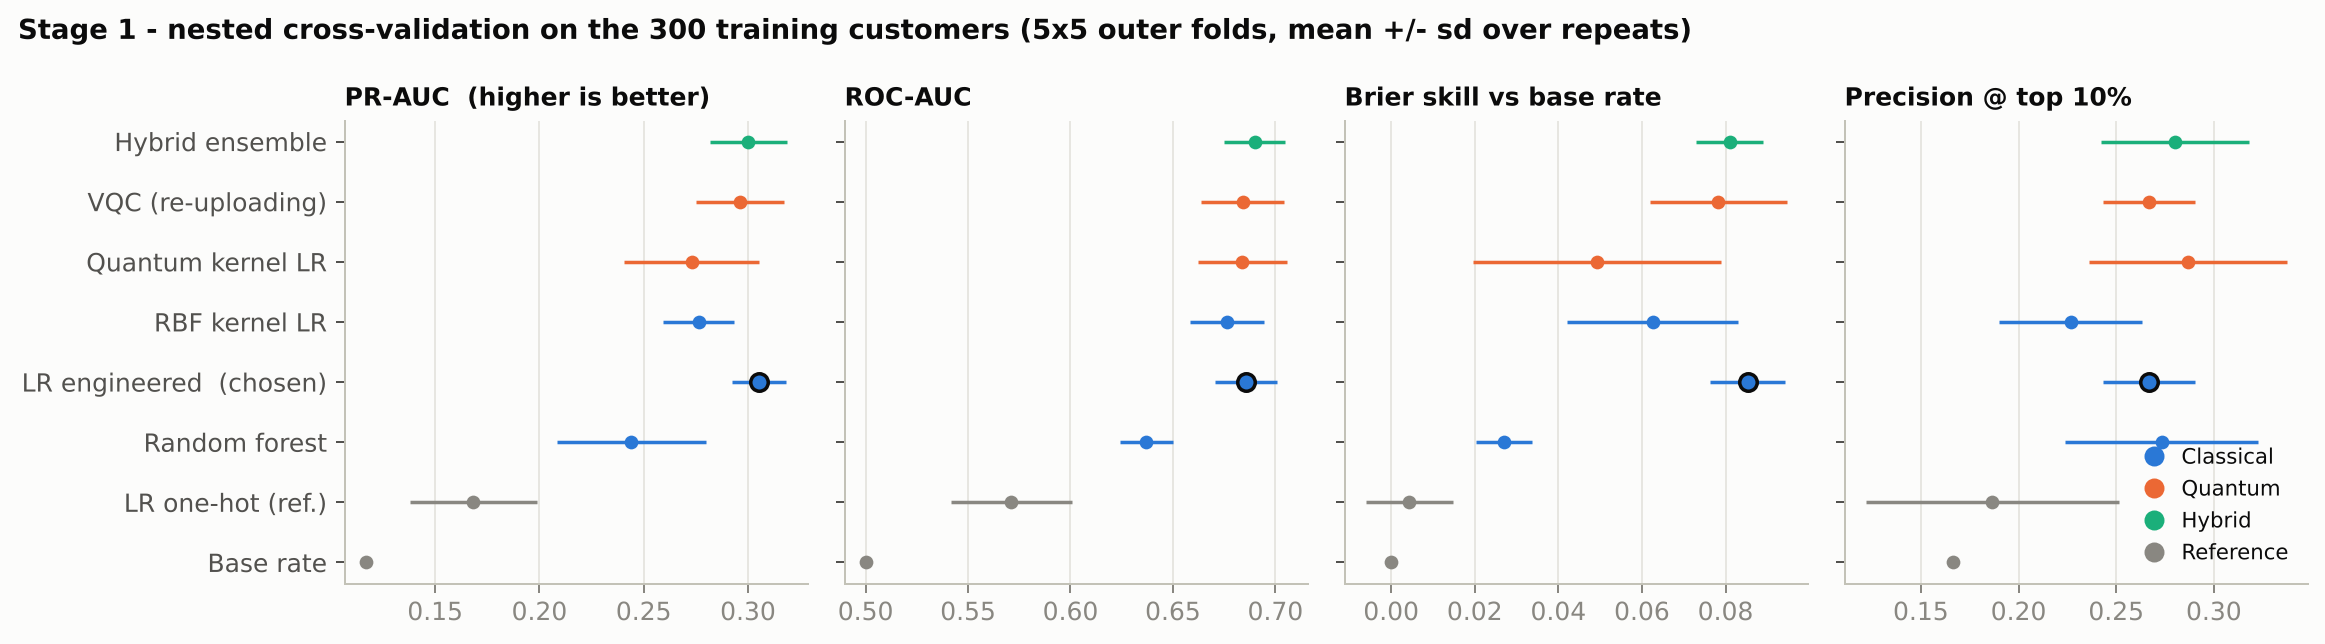

In [3]:
cv = pd.read_csv(R / "stage1_cv_metrics.csv", index_col=0)
cols = ["roc_auc", "pr_auc", "brier", "log_loss", "precision@10pct", "recall@10pct", "calib_slope"]
display(cv[cols + [c + "_sd" for c in ["roc_auc", "pr_auc", "brier", "log_loss"]]].round(4).sort_values("log_loss"))
print("chosen:", utils.load_json(R / "stage1_cv_details.json")["chosen_model"])
display(Image(R / "figures" / "stage1_cv_comparison.png"))

**Live check:** refit the production model on all training data and confirm it reproduces the submitted test probabilities.

In [4]:
from qcampaign import stage1
card = utils.load_json(R / "stage1_model_card.json")
model, comps = stage1.fit_production(d, card["chosen_model"])
live = stage1.predict_test(d, model)
sub = pd.read_csv(R / "stage1_predictions.csv")
m = live.merge(sub, on="customer_id", suffixes=("_live", "_file"))
print("max |p_live - p_file| =", float((m.predicted_probability_live - m.predicted_probability_file).abs().max()),
      "(the file stores 6 decimals)")
print("same ranking:", (m.rank_live == m.rank_file).all())
prod = comps[card["chosen_model"]]
print("selected features:", prod.selected_features())
print("standardised coefficients:", {k: round(float(v), 3) for k, v in prod.coefficients().items()})
sub.head(12)

max |p_live - p_file| = 4.942357607617964e-07 (the file stores 6 decimals)
same ranking: True
selected features: ['age', 'bal_slog', 'day', 'pout_success', 'pout_failure', 'month_is_mode']
standardised coefficients: {'age': -0.024, 'bal_slog': 0.268, 'day': -0.243, 'pout_success': 0.379, 'pout_failure': -0.196, 'month_is_mode': -0.397}


,customer_id,predicted_probability,rank,top10_flag
0,C0081,0.658662,1,1
1,C0031,0.652467,2,1
2,C0079,0.542857,3,1
3,C0183,0.210870,4,1
4,C0378,0.205553,5,1
5,C0170,0.187620,6,1
6,C0318,0.181930,7,1
7,C0087,0.171472,8,1
8,C0128,0.171338,9,1
9,C0397,0.169374,10,1


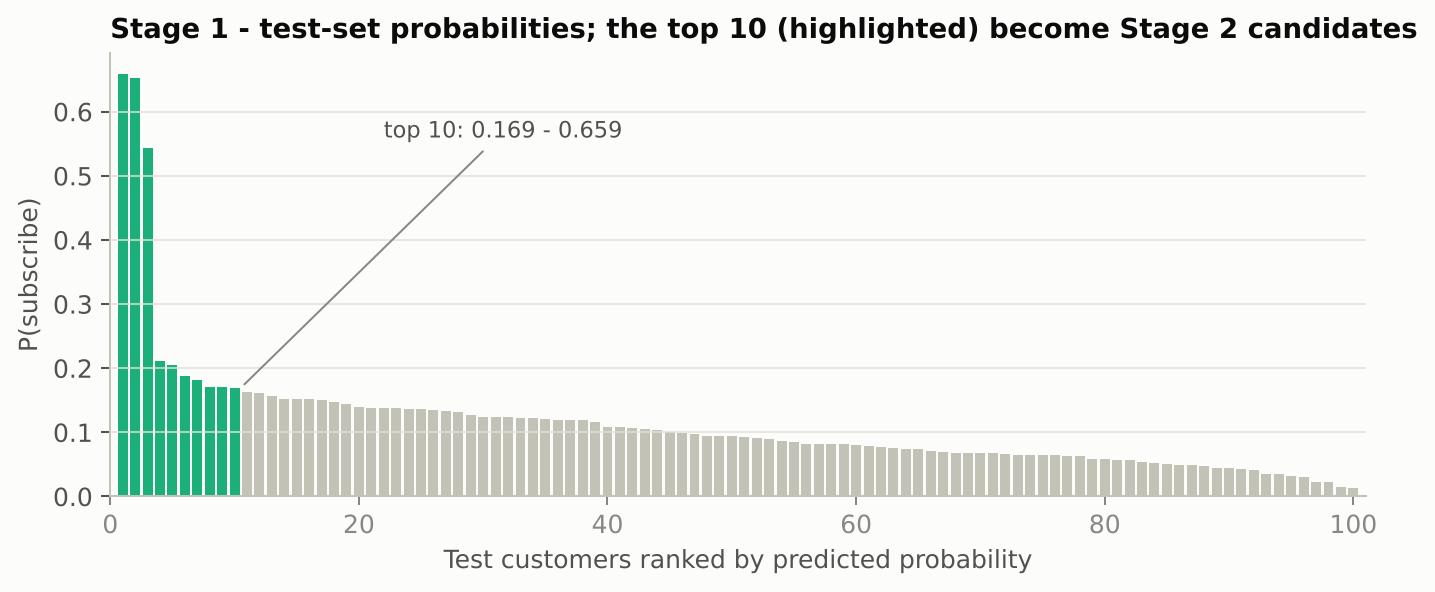

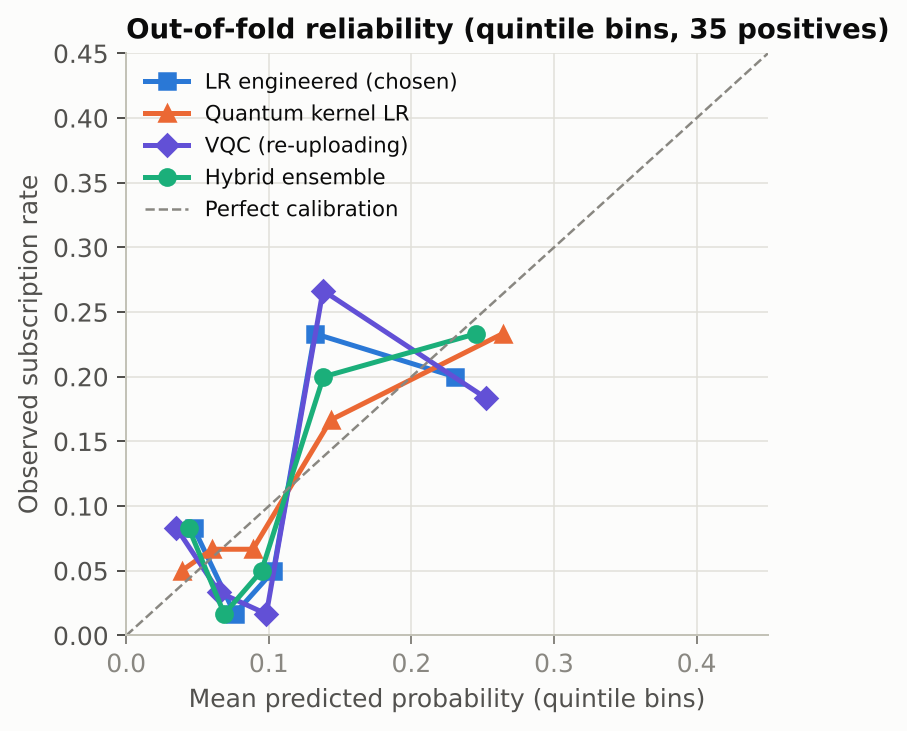

In [5]:
display(Image(R / "figures" / "stage1_test_ranking.png")); display(Image(R / "figures" / "stage1_calibration.png"))

## 2. Stage 2 - constrained selection (QAOA vs brute force)

Objective: maximise sum (p_i * deposit_i - cost_i) over exactly 6 of the top 10, subject to budget <= 25 and capacity <= 22.
Three formulations: full QUBO with slack registers (18 qubits here), presolved QUBO (10 qubits; inequalities proven
implied by the cardinality constraint for this candidate set), and constraint-preserving QAOA (Dicke state + XY mixer).

In [6]:
from qcampaign import stage2
from qcampaign.qaoa import build_qubo, verify_ground_state
top = stage2.load_candidates(d)
prob = stage2.make_problem(top, d.constraints)
feas, n_all = prob.brute_force()
print(f"live brute force: {len(feas)} feasible of {n_all}; optimum", [i for i, s in zip(prob.ids, feas[0]['x']) if s],
      round(feas[0]['objective'], 4))
full = build_qubo(prob, config.PENALTY_SAFETY, include_k_penalty=True, presolve=False)
print("full QUBO qubits:", full.n_vars, "slack registers:", full.slack, "penalty A =", round(full.penalties['A'], 3))
print(f"ground-state check over 2^{full.n_vars} states:", verify_ground_state(full, feas))
top

live brute force: 210 feasible of 1024; optimum ['C0081', 'C0031', 'C0079', 'C0170', 'C0087', 'C0397'] 33.0032
full QUBO qubits: 18 slack registers: {'budget': (10, [1, 2, 4, 8]), 'capacity': (14, [1, 2, 4, 8])} penalty A = 54.749
ground-state check over 2^18 states: {'ground_state_index': 210599, 'ground_state_bitstring': '110011011010100111', 'ground_energy': -33.003249000015785, 'ground_state_is_constrained_optimum': True, 'spectral_gap_to_next_distinct_solution': 1.1343160000105854, 'n_states_checked': 262144}


,customer_id,predicted_probability,rank,top10_flag,contact_cost,expected_deposit_value,capacity_units,customer_segment,expected_net_value,qubit
0,C0081,0.658662,1,1,4,17,1,C,7.197254,0
1,C0031,0.652467,2,1,2,13,1,D,6.482071,1
2,C0079,0.542857,3,1,3,24,3,A,10.028568,2
3,C0183,0.210870,4,1,2,14,3,B,0.952180,3
4,C0378,0.205553,5,1,3,14,1,D,-0.122258,4
5,C0170,0.187620,6,1,1,22,1,C,3.127640,5
6,C0318,0.181930,7,1,3,21,3,A,0.820530,6
7,C0087,0.171472,8,1,1,18,1,D,2.086496,7
8,C0128,0.171338,9,1,4,14,2,A,-1.601268,8
9,C0397,0.169374,10,1,1,30,3,C,4.081220,9


{
 "selected_ids": [
  "C0081",
  "C0031",
  "C0079",
  "C0170",
  "C0087",
  "C0397"
 ],
 "selected_bitstring_decision_register": "1010100111",
 "selection_vector_rank_order": "1110010101",
 "selected_by": "presolved_xy_dicke p=3 (ideal Aer, 8192 shots)",
 "objective_value": 33.003249,
 "budget_used": 12.0,
 "budget_limit": 25.0,
 "capacity_used": 10.0,
 "capacity_limit": 22.0,
 "n_selected": 6,
 "feasible": true,
 "classical_optimum_ids": [
  "C0081",
  "C0031",
  "C0079",
  "C0170",
  "C0087",
  "C0397"
 ],
 "classical_optimum_objective": 33.003249,
 "gap_absolute": 0.0,
 "gap_relative": 0.0,
 "second_best_objective": 31.868933,
 "n_feasible_selections": 210,
 "n_assignments_enumerated": 1024,
 "random_baselines": {
  "uniform_bits_p_optimal": 0.0009765625,
  "uniform_bits_p_feasible": 0.205078125,
  "uniform_K_subsets_p_optimal": 0.004761904761904762,
  "uniform_K_subsets_p_feasible": 1.0
 }
}


,variant,p,mode,shots,p_optimal_sampled,p_feasible_sampled,distinct_bitstrings,best_feasible_selection,best_feasible_bitstring,best_feasible_objective,best_feasible_count,most_frequent_feasible_selection,most_frequent_feasible_objective
0,full_penalty_x,1,ideal_shots,8192.0,0.0009,0.3129,7820.0,1.110010e+09,1.111111e+15,33.0032,1.0,1.000101e+09,12.4620
1,full_penalty_x,2,ideal_shots,8192.0,0.0011,0.3036,7467.0,1.110010e+09,1.111101e+17,33.0032,1.0,1.111000e+09,27.1400
2,presolved_penalty_x,1,ideal_shots,8192.0,0.0032,0.6438,934.0,1.110010e+09,1.010100e+09,33.0032,26.0,1.100101e+09,14.8628
3,presolved_penalty_x,2,ideal_shots,8192.0,0.0040,0.7910,665.0,1.110010e+09,1.010100e+09,33.0032,33.0,1.111100e+09,28.6190
4,presolved_penalty_x,3,ideal_shots,8192.0,0.0109,0.6421,809.0,1.110010e+09,1.010100e+09,33.0032,89.0,1.111010e+09,31.8689
5,presolved_xy_dicke,1,ideal_shots,8192.0,0.0594,1.0000,195.0,1.110010e+09,1.010100e+09,33.0032,487.0,1.110010e+09,33.0032
6,presolved_xy_dicke,2,ideal_shots,8192.0,0.1113,1.0000,195.0,1.110010e+09,1.010100e+09,33.0032,912.0,1.110010e+09,33.0032
7,presolved_xy_dicke,3,ideal_shots,8192.0,0.1555,1.0000,197.0,1.110010e+09,1.010100e+09,33.0032,1274.0,1.110010e+09,33.0032
8,presolved_penalty_x,1,noisy_FakeTorino,8192.0,0.0022,0.4263,1001.0,1.110010e+09,1.010100e+09,33.0032,18.0,1.010101e+09,18.4093
9,presolved_penalty_x,1,noisy_FakeTorino_readout_mitigated,NaN,0.0026,0.4846,NaN,NaN,NaN,NaN,NaN,NaN,NaN


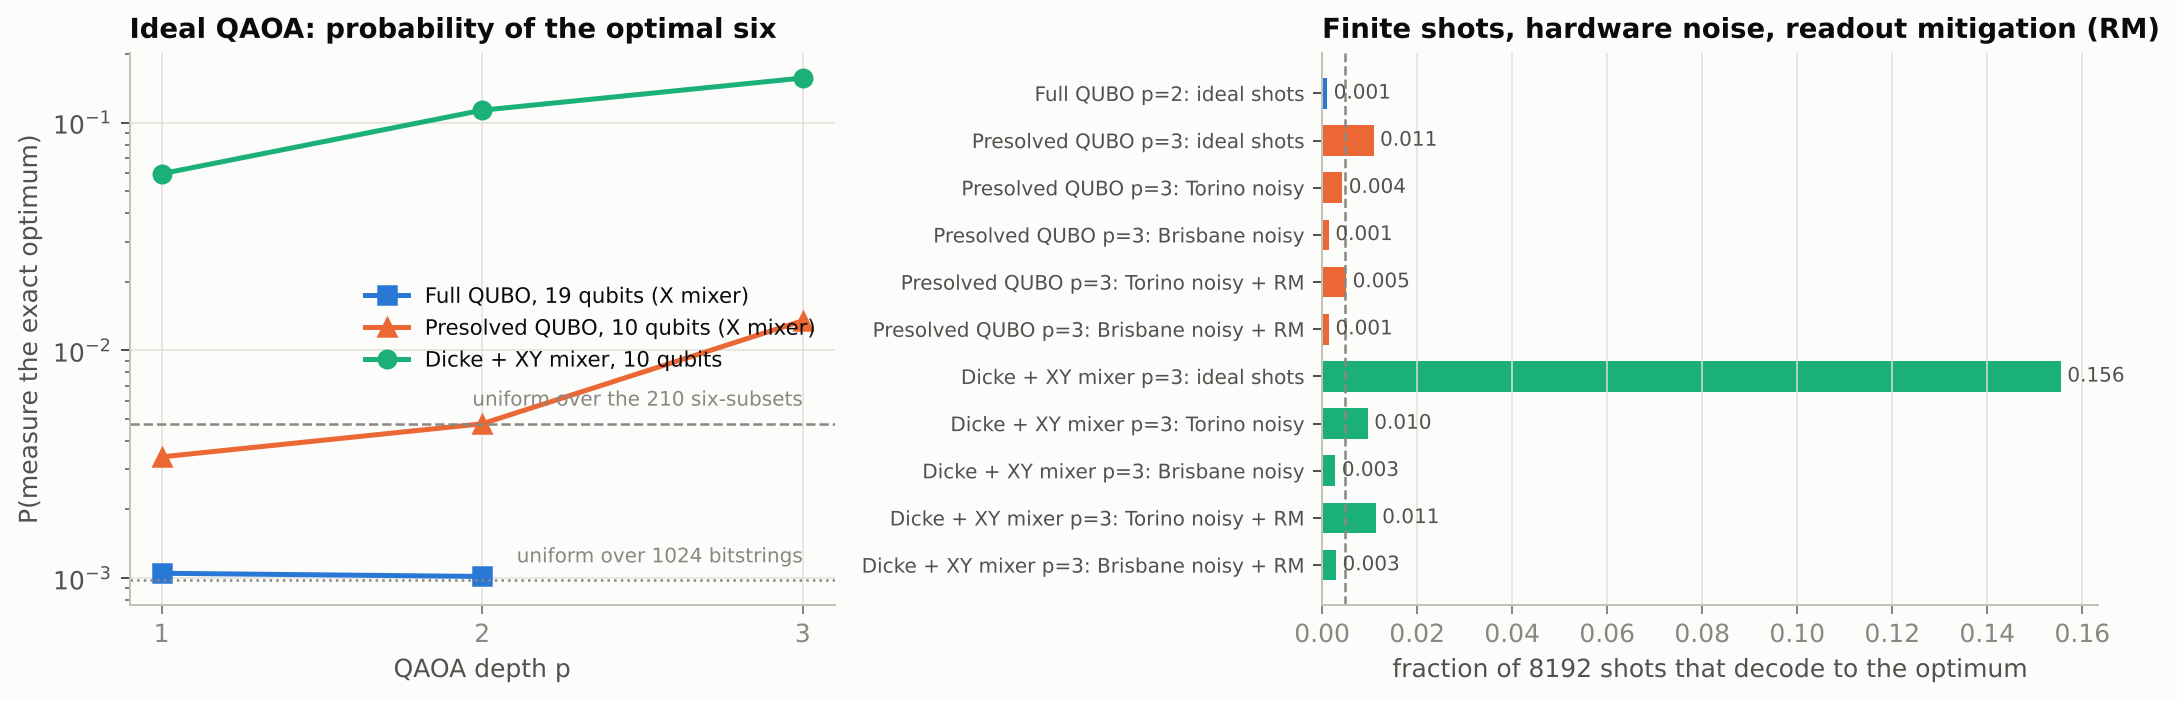

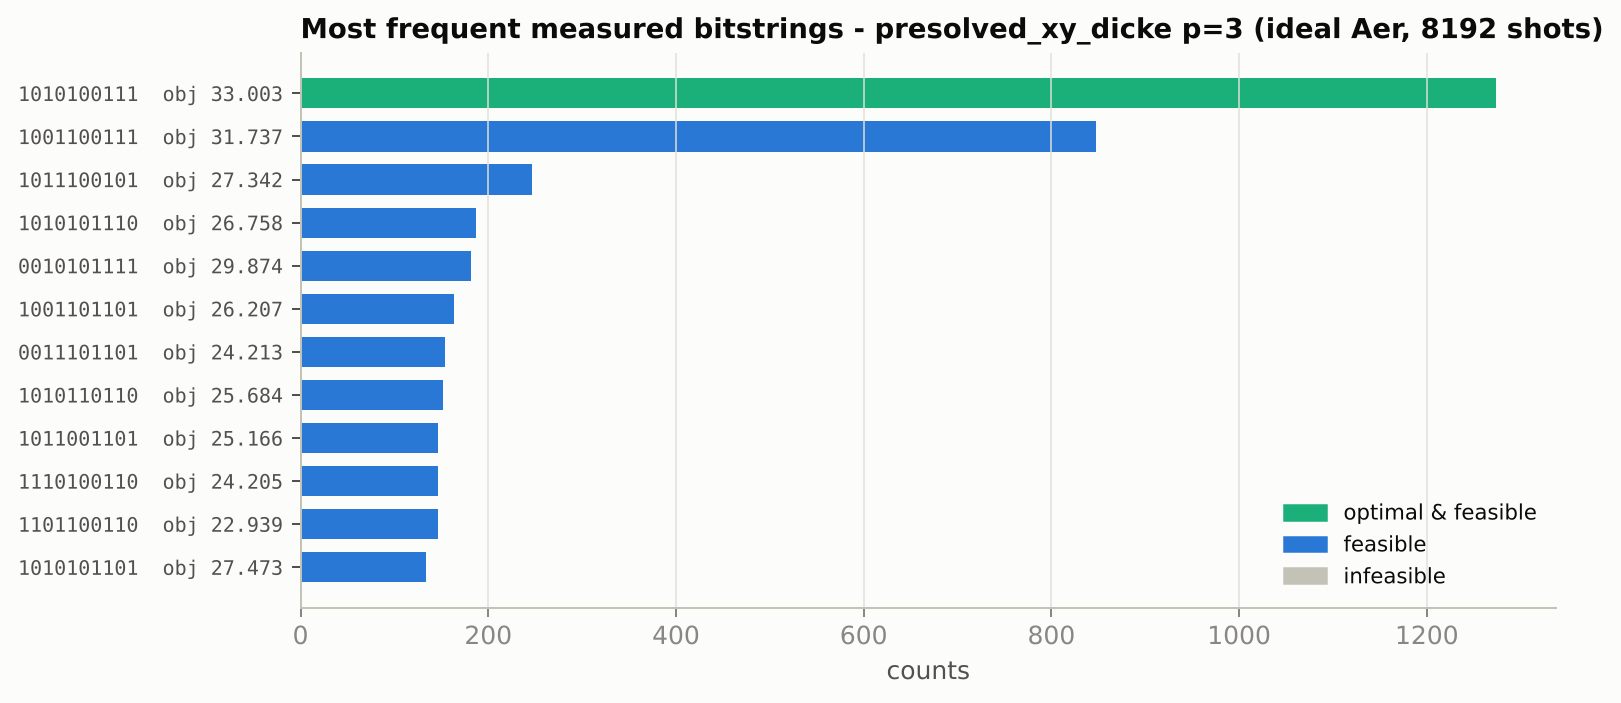

In [7]:
det = utils.load_json(R / "stage2_details.json")
print(json.dumps(det["summary"], indent=1))
display(pd.read_csv(R / "stage2_runs.csv").round(4))
display(Image(R / "figures" / "stage2_qaoa.png")); display(Image(R / "figures" / "stage2_bitstrings.png"))

In [8]:
print("Optimised QAOA parameters (gamma in normalised-energy units):")
for v, o in det["optimisation"].items():
    for p, r in o.items():
        print(f"  {v:22s} p={p}: gammas={np.round(r['gammas'], 4).tolist()} betas={np.round(r['betas'], 4).tolist()} "
              f"P(opt)={r['quality_exact']['p_optimal']:.4f}")
pd.read_csv(R / "stage2_top_bitstrings.csv", dtype={"bitstring": str, "selection": str}).head(10)

Optimised QAOA parameters (gamma in normalised-energy units):
  full_penalty_x         p=1: gammas=[-0.6325] betas=[0.2676] P(opt)=0.0010
  full_penalty_x         p=2: gammas=[-0.4458, -1.7869] betas=[0.4778, 0.202] P(opt)=0.0010
  presolved_penalty_x    p=1: gammas=[-0.5291] betas=[0.2012] P(opt)=0.0034
  presolved_penalty_x    p=2: gammas=[-0.3228, -1.4932] betas=[0.2459, 0.0874] P(opt)=0.0048
  presolved_penalty_x    p=3: gammas=[-0.4194, -1.2894, -0.7106] betas=[0.2637, 0.375, 0.3004] P(opt)=0.0135
  presolved_xy_dicke     p=1: gammas=[-1.2048] betas=[0.6056] P(opt)=0.0596
  presolved_xy_dicke     p=2: gammas=[0.821, 1.719] betas=[-0.7883, 2.701] P(opt)=0.1133
  presolved_xy_dicke     p=3: gammas=[-0.7403, -1.5036, 0.3561] betas=[0.7861, 0.7534, -0.5143] P(opt)=0.1568


,bitstring,count,freq,selection,n_selected,cost,capacity,objective,feasible,selected_ids
0,1010100111,1274,0.155518,1110010101,6,12.0,10.0,33.003249,True,C0081 C0031 C0079 C0170 C0087 C0397
1,1001100111,848,0.103516,1110011001,6,14.0,12.0,31.737283,True,C0081 C0031 C0079 C0170 C0318 C0397
2,1011100101,247,0.030151,1010011101,6,13.0,12.0,27.341708,True,C0081 C0079 C0170 C0318 C0087 C0397
3,1010101110,187,0.022827,0111010101,6,10.0,12.0,26.758175,True,C0031 C0079 C0183 C0170 C0087 C0397
4,0010101111,182,0.022217,1111010100,6,13.0,10.0,29.874209,True,C0081 C0031 C0079 C0183 C0170 C0087
5,1001101101,163,0.019897,1011011001,6,14.0,14.0,26.207392,True,C0081 C0079 C0183 C0170 C0318 C0397
6,0011101101,154,0.018799,1011011100,6,14.0,12.0,24.212668,True,C0081 C0079 C0183 C0170 C0318 C0087
7,1010110110,152,0.018555,0110110101,6,11.0,10.0,25.683737,True,C0031 C0079 C0378 C0170 C0087 C0397
8,1011001101,146,0.017822,1011001101,6,14.0,14.0,25.166248,True,C0081 C0079 C0183 C0318 C0087 C0397
9,1110100110,146,0.017822,0110010111,6,12.0,11.0,24.204727,True,C0031 C0079 C0170 C0087 C0128 C0397


## 3. Stage 3 - P(at least 3 of 6 subscribe)

One qubit per customer, RY(2 arcsin sqrt(p)) so P(1) = p. Qubit order = ascending Stage-1 rank; Qiskit bitstrings are
little-endian (rightmost character = q0).

,customer_id,predicted_probability,rank,top10_flag,qubit,theta_ry
0,C0081,0.658662,1,1,0,1.893703
1,C0031,0.652467,2,1,1,1.880665
2,C0079,0.542857,3,1,2,1.656616
3,C0170,0.187620,6,1,3,0.895972
4,C0087,0.171472,8,1,4,0.853890
5,C0397,0.169374,10,1,5,0.848310


live exact Poisson-binomial: 0.45054844886299383
         ┌────────────┐ ░ ┌─┐               
   q_0: ─┤ Ry(1.8937) ├─░─┤M├───────────────
         ├────────────┤ ░ └╥┘┌─┐            
   q_1: ─┤ Ry(1.8807) ├─░──╫─┤M├────────────
         ├────────────┤ ░  ║ └╥┘┌─┐         
   q_2: ─┤ Ry(1.6566) ├─░──╫──╫─┤M├─────────
        ┌┴────────────┤ ░  ║  ║ └╥┘┌─┐      
   q_3: ┤ Ry(0.89597) ├─░──╫──╫──╫─┤M├──────
        ├─────────────┤ ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ┤ Ry(0.85389) ├─░──╫──╫──╫──╫─┤M├───
        ├─────────────┤ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ┤ Ry(0.84831) ├─░──╫──╫──╫──╫──╫─┤M├
        └─────────────┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/═══════════════════╩══╩══╩══╩══╩══╩═
                           0  1  2  3  4  5 
{
 "exact_poisson_binomial": 0.45054844886299383,
 "statevector_probability": 0.4505484488629939,
 "quantum_estimate_ideal_shots": 0.4515380859375,
 "quantum_ci95_wilson": [
  0.44078690598727716,
  0.4623346948900075
 ],
 "quantum_abs_error": 0.0009896370745061667,
 "monte_c

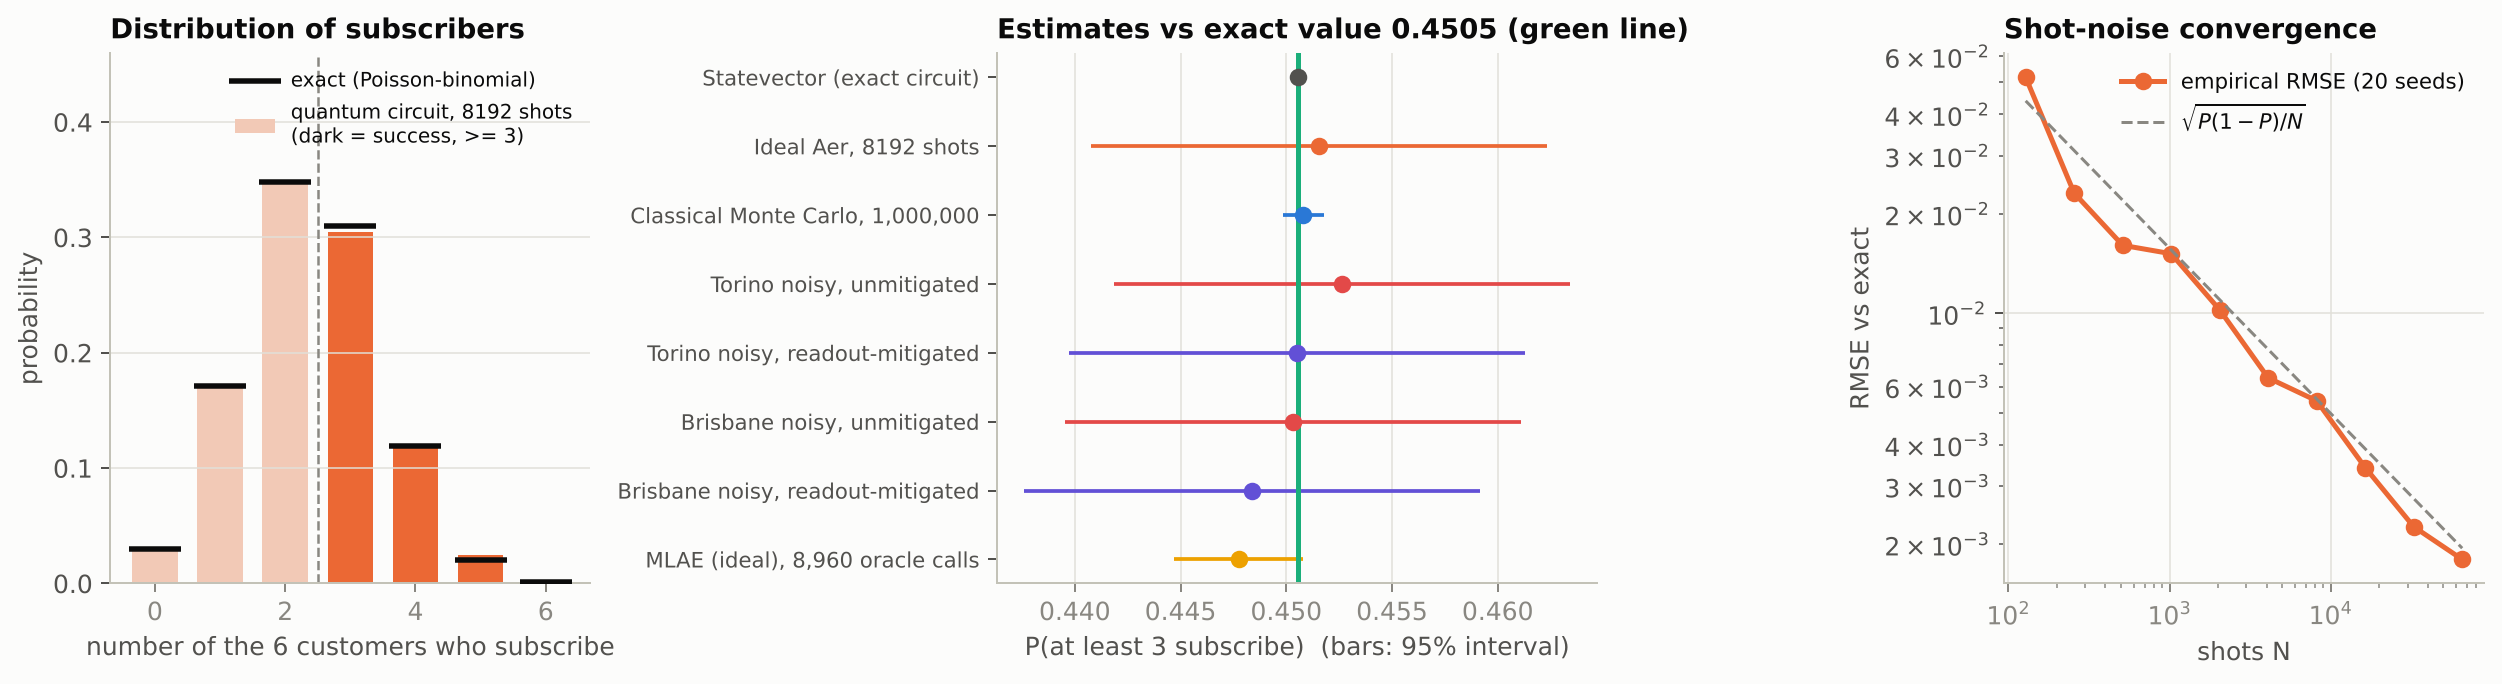

In [9]:
from qcampaign import stage3
s3 = utils.load_json(R / "stage3_details.json")
sel = stage3.load_selection(d)
display(sel)
p = sel.predicted_probability.to_numpy()
print("live exact Poisson-binomial:", stage3.exact_at_least(p, 3))
print(stage3.prep_circuit(p).draw(output="text"))
keys = ["exact_poisson_binomial", "statevector_probability", "quantum_estimate_ideal_shots", "quantum_ci95_wilson",
        "quantum_abs_error", "monte_carlo_estimate", "monte_carlo_abs_error"]
print(json.dumps({k: s3[k] for k in keys}, indent=1))
print({b: {k: round(v[k], 5) for k in ["estimate_unmitigated", "estimate_readout_mitigated"]} for b, v in s3["noisy"].items()})
display(Image(R / "figures" / "stage3_results.png"))

## 4. Error propagation across stages (bootstrap of the training data)

{
 "n_bootstrap": 100,
 "resampling": "stratified bootstrap of the 300 training customers; hyper-parameters frozen",
 "our_top10_mean_membership": 0.562,
 "our_six_selected_identically": 0.1,
 "our_six_mean_selection_frequency": 0.6383333333333333,
 "p_ge3_point_estimate": 0.45054844886299383,
 "p_ge3_fixed_six": {
  "mean": 0.43031418998571397,
  "sd": 0.16187329702711342,
  "q05": 0.12156426725200459,
  "q50": 0.4552853192886426,
  "q95": 0.6715954278012423
 },
 "p_ge3_reoptimised_six": {
  "mean": 0.4910806219083899,
  "sd": 0.1543155458770783,
  "q05": 0.20059199398797134,
  "q50": 0.4981108559832438,
  "q95": 0.7093195691166072
 },
 "quantum_shot_noise_sd": 0.0054982623640652635,
 "ratio_model_sd_to_shot_sd": 29.4408098975162,
 "seconds": 6.474653720855713
}


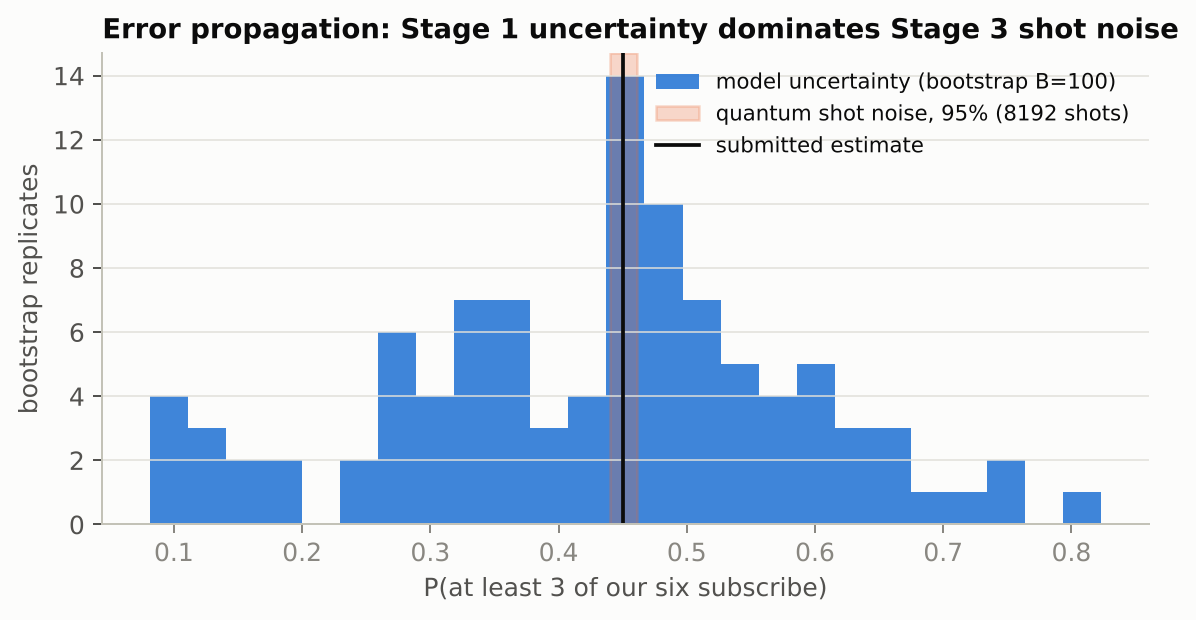

In [10]:
u = utils.load_json(R / "uncertainty_propagation.json")
print(json.dumps({k: v for k, v in u.items() if not k.endswith("draws")}, indent=1))
display(Image(R / "figures" / "uncertainty_propagation.png"))

## 5. Correctness tests

In [11]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(ROOT / "tests")],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-800:])

............                                                             [100%]
12 passed in 1.18s

